# BDA500 Project 1: Airbnb NYC Rental Price Prediction

**Group Number:** 2

**Team members:** Fatemeh Sayah Taheri, Mahashree Jatinbhai Ajmeri

**Dataset:** New York City Airbnb Open Data (Kaggle)

**Due:** October 14, 2026, 11:59 PM ET

## 0. Setup

**Question:** Which libraries, paths, target, identifiers, dates, leakage columns, and random settings are required?

In [1]:
from pathlib import Path

import warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler,
    PolynomialFeatures, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)

warnings.filterwarnings('ignore')
np.random.seed(42)

DATA_PATH = Path("AB_NYC_2019.csv")
TARGET = "price"

ID_COLUMNS = ["id", "host_id"]
DATE_COLUMNS = ["last_review"]
LEAKAGE_COLUMNS = []

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries loaded")

Libraries loaded


## 1. Problem Framing

**Question:** What continuous value will be predicted in supervised learning? What variables will be used for prediction?

In [2]:
y = "price"

feature_cols = [
    "neighbourhood_group",
    "room_type",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

## 2.1 Load and Inspect
**Question**: What are the head, shape, structure, data types, summary statistics, and missing-value counts

In [3]:
df = pd.read_csv(DATA_PATH)
df = df.sample(n=5000, random_state=42).copy()

display(df.head())
print("Shape:", df.shape)
df.info()

display(df.dtypes.to_frame("Dtype"))
display(df.describe(include="all").T)

missing = pd.DataFrame({
    "Count": df.isna().sum(),
    "Percent": df.isna().mean() * 100
})

display(missing[missing.Count > 0].sort_values("Percent", ascending=False))

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
879,317905,Come and go as you please in BKLN!,1631733,Jane,Brooklyn,Kensington,40.64354,-73.97777,Entire home/apt,89,3,62,2019-01-02,0.71,1,189
44383,34205267,"Spacious, sunny room in Queens/Brooklyn",913940,Giancarlo,Queens,Ridgewood,40.70666,-73.90779,Private room,30,21,0,NaN,NaN,1,73
15394,12342297,Private bedroom in high-ceiling 4BR apartment!,19953913,Alejandro,Manhattan,Hell's Kitchen,40.76116,-73.99016,Private room,120,2,17,2017-04-28,0.43,1,0
43230,33527778,Sonder | Stock Exchange | Stunning 3BR + Kitchen,219517861,Sonder (NYC),Manhattan,Financial District,40.70763,-74.01050,Entire home/apt,470,2,5,2019-06-02,1.88,327,272
16332,13136376,Spacious 2 Bedroom with Balcony,16110448,Gingie,Manhattan,East Harlem,40.79658,-73.93287,Entire home/apt,199,2,30,2019-06-03,0.80,1,30


Shape: (5000, 16)
<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 879 to 11762
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              5000 non-null   int64  
 1   name                            4996 non-null   object 
 2   host_id                         5000 non-null   int64  
 3   host_name                       4998 non-null   object 
 4   neighbourhood_group             5000 non-null   object 
 5   neighbourhood                   5000 non-null   object 
 6   latitude                        5000 non-null   float64
 7   longitude                       5000 non-null   float64
 8   room_type                       5000 non-null   object 
 9   price                           5000 non-null   int64  
 10  minimum_nights                  5000 non-null   int64  
 11  number_of_reviews               5000 non-null   int64  
 12  last_review       

,Dtype
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5000.0,NaN,NaN,NaN,19129116.0462,10915826.10334,5022.0,9684791.25,19866880.5,29183526.75,36479230.0
name,4996,4970,Private room in Manhattan,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,5000.0,NaN,NaN,NaN,67304183.0802,77774619.770356,2787.0,7888663.0,31842427.0,105950987.0,274195458.0
host_name,4998,2494,David,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,5000,5,Manhattan,2131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,5000,182,Williamsburg,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,5000.0,NaN,NaN,NaN,40.728155,0.054884,40.53884,40.689575,40.72252,40.762637,40.90734
longitude,5000.0,NaN,NaN,NaN,-73.951201,0.046119,-74.19826,-73.982647,-73.955075,-73.934487,-73.7169
room_type,5000,3,Entire home/apt,2566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,5000.0,NaN,NaN,NaN,148.7078,246.528892,0.0,65.0,100.0,174.0,10000.0


,Count,Percent
reviews_per_month,1038,20.76
last_review,1038,20.76
name,4,0.08
host_name,2,0.04


## 2.2 Column Roles and Cleaning
**Question**: Which columns are numeric, categorical, identifiers, dates, target, or leakage, and how are duplicates/removals handled?

In [4]:
numeric = df.select_dtypes(include=np.number).columns.tolist()

roles = pd.DataFrame({
    "Column": df.columns,
    "Dtype": df.dtypes.astype(str).values
})

roles["Role"] = [
    "Target" if x == TARGET
    else "Identifier" if x in ID_COLUMNS
    else "Date" if x in DATE_COLUMNS
    else "Leakage" if x in LEAKAGE_COLUMNS
    else "Numeric" if x in numeric
    else "Categorical"
    for x in df.columns
]

display(roles)

print("Duplicates:", df.duplicated().sum())

before = len(df)

df = df.drop_duplicates().copy()

removal_log = pd.DataFrame([
    {
        "Action": "Drop exact duplicates",
        "Count": before - len(df),
        "Reason": "Exact duplicate records"
    }
])

display(removal_log)


,Column,Dtype,Role
0,id,int64,Identifier
1,name,object,Categorical
2,host_id,int64,Identifier
3,host_name,object,Categorical
4,neighbourhood_group,object,Categorical
5,neighbourhood,object,Categorical
6,latitude,float64,Numeric
7,longitude,float64,Numeric
8,room_type,object,Categorical
9,price,int64,Target


Duplicates: 0


,Action,Count,Reason
0,Drop exact duplicates,0,Exact duplicate records


## 3.1 Histograms and Boxplots
**Question**: What do important numeric distributions and boxplots reveal about spread, skewness, and outliers?

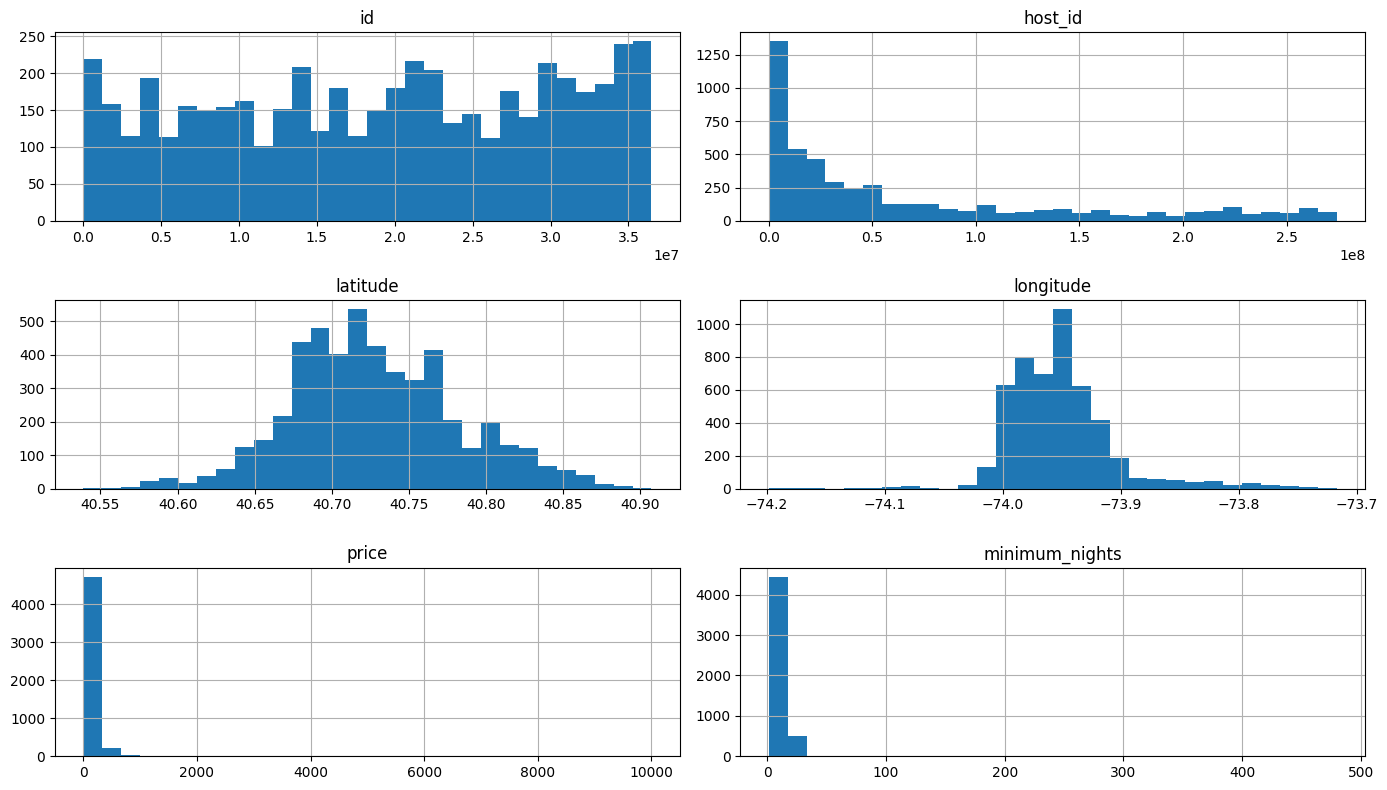

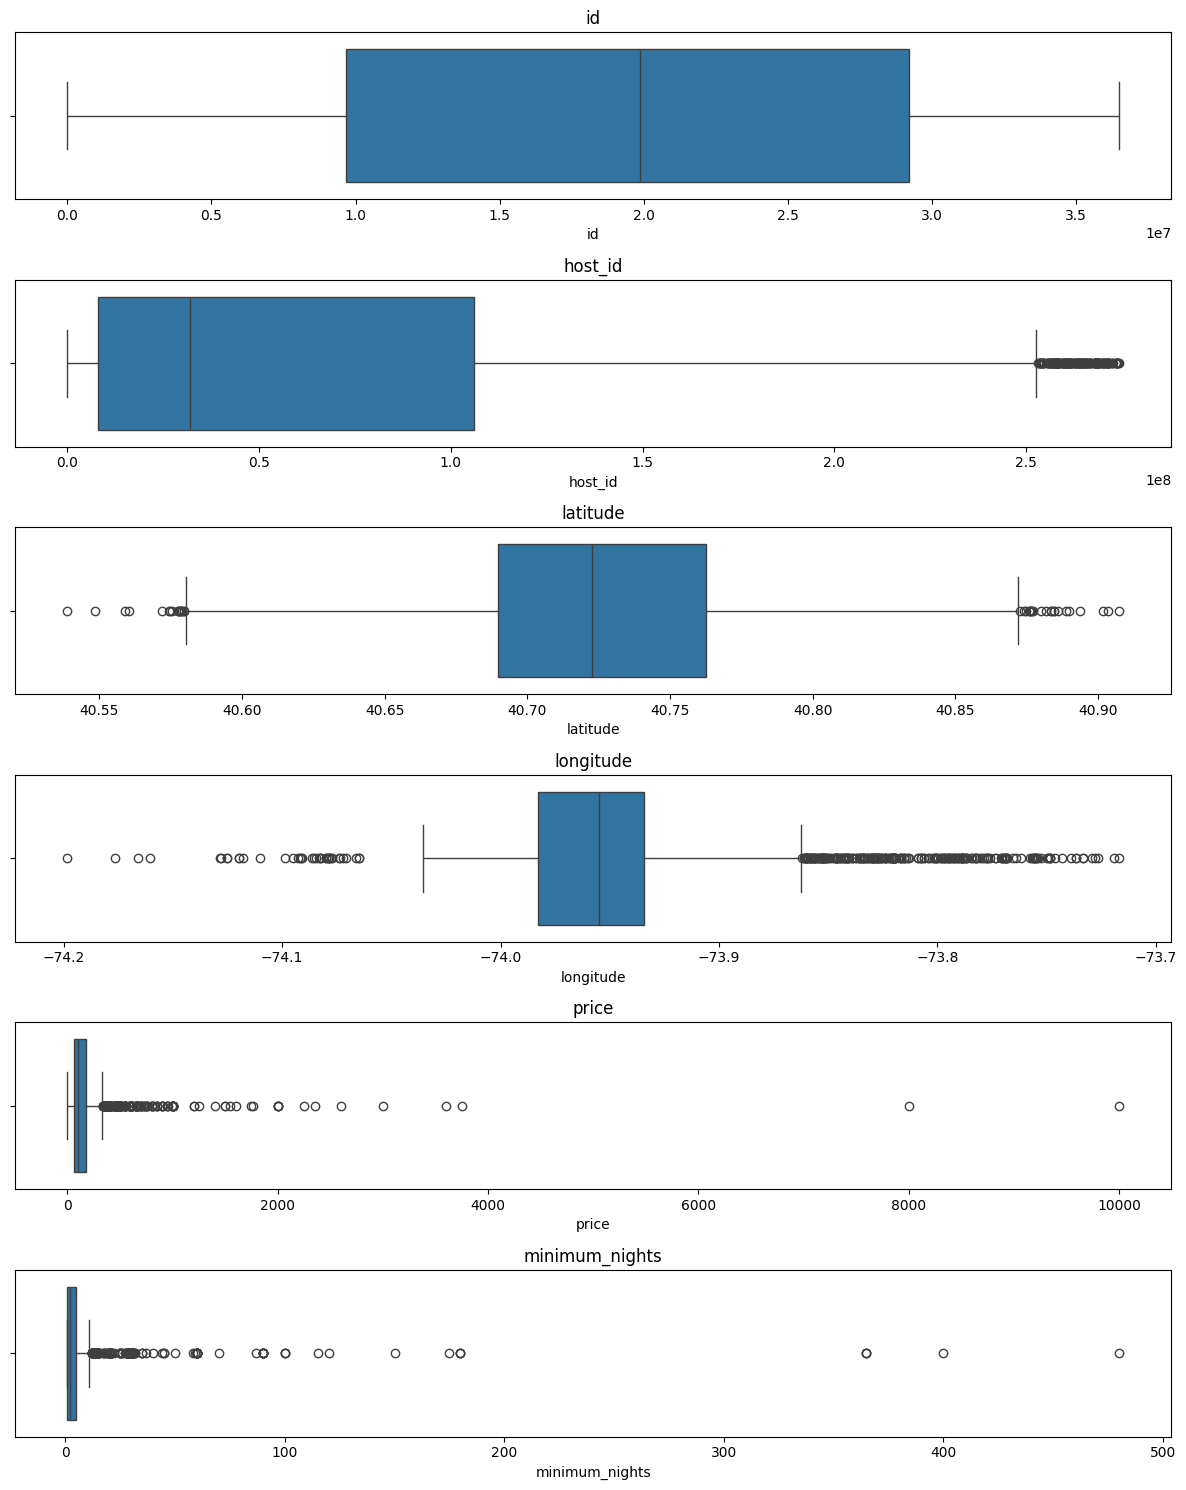

In [5]:
important_numeric = [x for x in numeric if x in df.columns][:6]

df[important_numeric].hist(figsize=(14, 8), bins=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(important_numeric), 1, figsize=(12, 2.5 * len(important_numeric)))

for ax, col in zip(np.atleast_1d(axes), important_numeric):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 3.2 Correlations and Target Relationships
**Question**: Which numeric variables correlate, and how do at least two important predictors relate to the target?

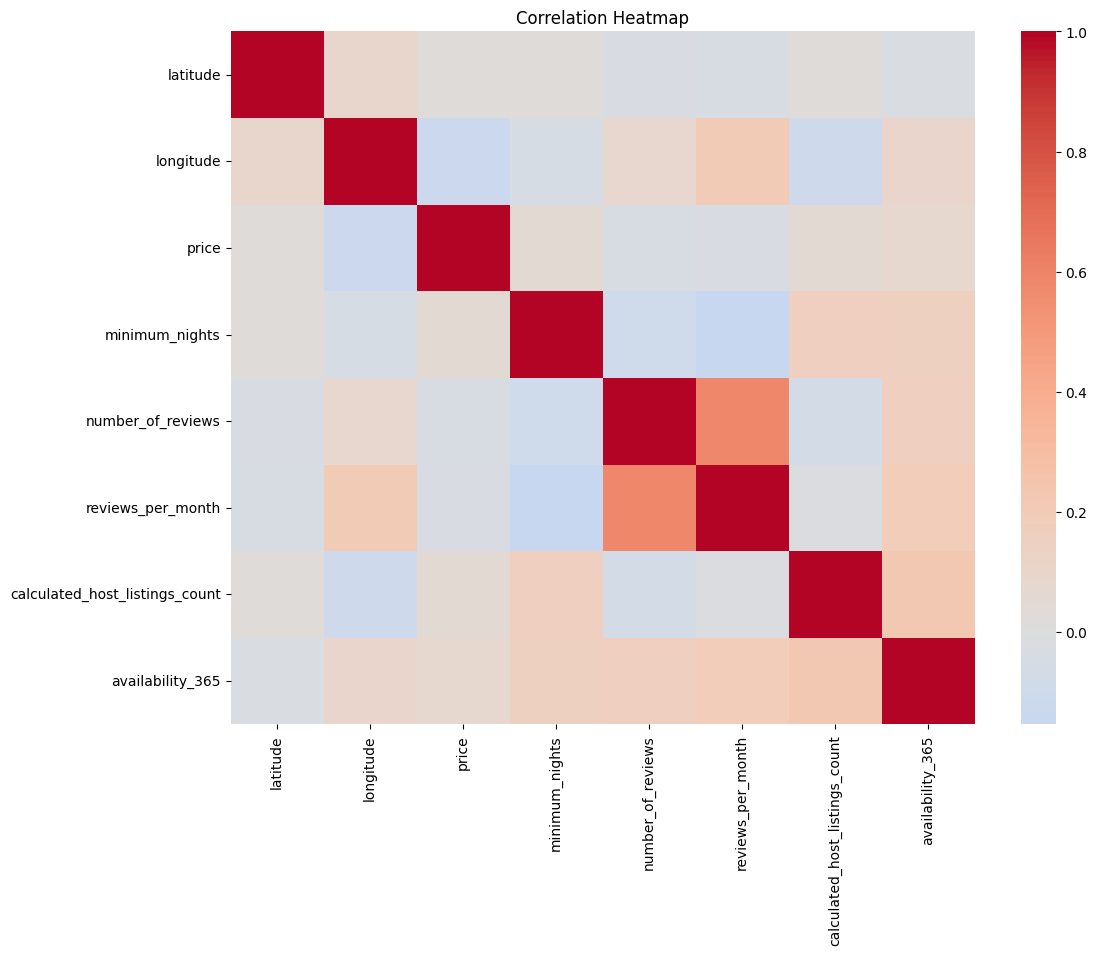

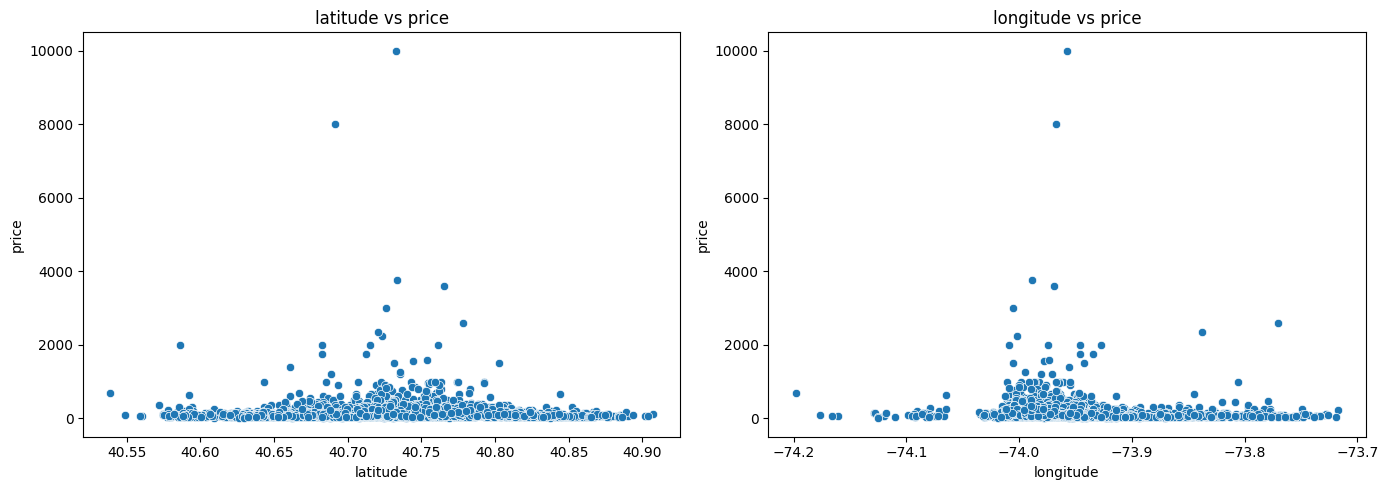

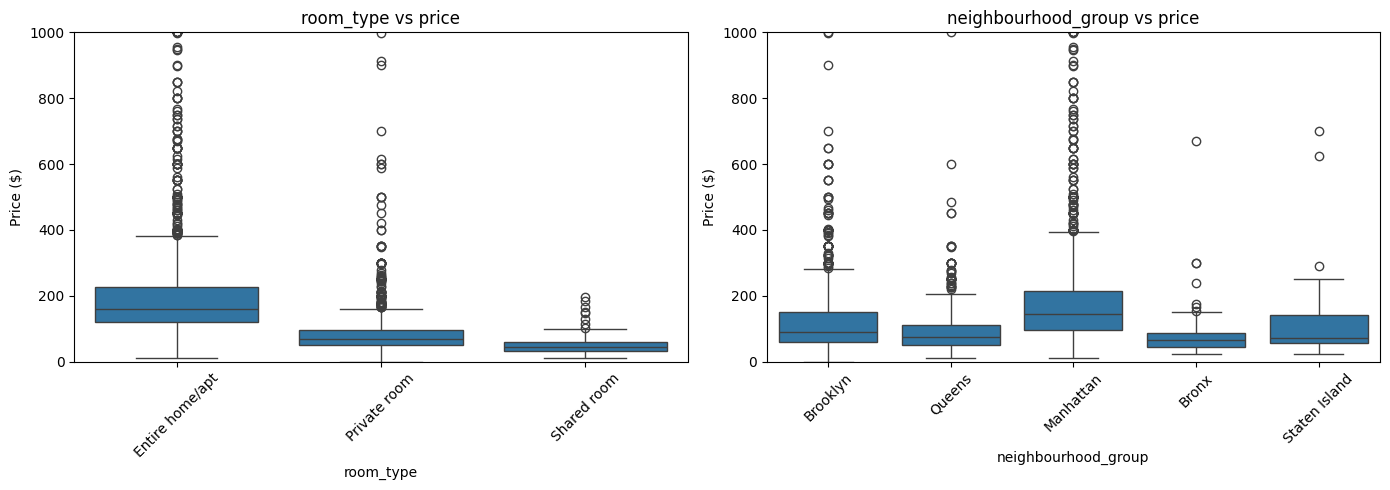

In [6]:
corr_cols = [x for x in df.select_dtypes(include=np.number).columns if x not in ID_COLUMNS]

plt.figure(figsize=(12, 9))
sns.heatmap(df[corr_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

predictors = [x for x in corr_cols if x != TARGET][:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, predictors):
    sns.scatterplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"{col} vs {TARGET}")

plt.tight_layout()
plt.show()

predictors = ["room_type", "neighbourhood_group"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, predictors):
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"{col} vs {TARGET}")
    ax.set_xlabel(col)
    ax.set_ylabel("Price ($)")
    ax.set_ylim(0, 1000)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 4. Preprocessing
**Question**: How are missing values, categorical encoding, and numeric scaling performed?

In [7]:
df_model = df.drop(columns=ID_COLUMNS + DATE_COLUMNS + LEAKAGE_COLUMNS, errors="ignore").copy()
df_model = df_model.dropna(subset=[TARGET]).copy()
X = df_model.drop(columns=TARGET)
y = df_model[TARGET]

In [8]:
X = X[feature_cols].copy()

In [9]:
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features)
])

## 6.1 Regression Configuration Counts

**Question:** How many configurations result from test sizes 10%, 25%, 30%; random states 0 and 42; five-fold CV; alpha 1; and polynomial degrees  3?

In [10]:
test_sizes= [0.10, 0.25, 0.30]
random_states=[0,42]
alpha=1
degree=3
cv_folds=5
model_names=["Linear","Polynomial","Ridge"]

configurations=0
for test_size in test_sizes:
    for random_state in random_states:
            configurations+=1
for model_name in model_names:
    print(f"Total Configurations: for {model_name}", configurations)

Total Configurations: for Linear 6
Total Configurations: for Polynomial 6
Total Configurations: for Ridge 6


## 6.2 Cross-Validated Regression Results

**Question:** What are mean and standard deviation of CV MAE, RMSE, and R-squared for every required configuration?

In [11]:

from sklearn.base import BaseEstimator, TransformerMixin

# Define candidate predictors
X = df_model[corr_cols].drop(columns=[TARGET]).copy()

# Reserve the final test set before model comparison
final_test_size = 0.10
final_random_state = 42

X_development, X_final_test, y_development, y_final_test = train_test_split(
    X,
    y,
    test_size=final_test_size,
    random_state=final_random_state
)

print("Development data:", X_development.shape)
print("Final test data:", X_final_test.shape)


# Select top 5 predictors using training data only
class Top5Selector(BaseEstimator, TransformerMixin):
    def fit(self, X, y):
        correlations = X.corrwith(pd.Series(
            np.asarray(y), index=X.index
        )).abs()

        self.predictors_ = (
            correlations.sort_values(ascending=False)
            .head(5)
            .index.tolist()
        )
        return self

    def transform(self, X):
        return X[self.predictors_]


# Display top 5 predictors for exploration only
corr_matrix = df[corr_cols].corr()

predictors = (
    corr_matrix[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

print("Top 5 predictors (EDA only):", predictors)


# Preprocessing for the five selected numerical predictors
preprocessor = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

# Define a pipeline function to run all models
def regression_pipeline(model_name, degree=3, alpha=1.0):
    steps = [
        ("feature_selection", Top5Selector()),
        ("preprocessor", preprocessor)
    ]

    if model_name == "Linear":
        steps.append(("regressor", LinearRegression()))

    elif model_name == "Ridge":
        steps.append(("regressor", Ridge(alpha=alpha)))

    elif model_name == "Polynomial":
        steps.append((
            "poly",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ))
        steps.append(("regressor", LinearRegression()))

    return Pipeline(steps)


records = []
splits = {}

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

for test_size in test_sizes:
    for random_state in random_states:

        X_train, X_test, y_train, y_test = train_test_split(
            X_development, y_development,
            test_size=test_size,
            random_state=random_state
)

        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        splits[(test_size, random_state)] = (
            X_train, X_test, y_train, y_test
        )

        for model_name in model_names:

            res = cross_validate(
                regression_pipeline(
                    model_name,
                    degree=3,
                    alpha=1.0
                ),
                X_train,
                y_train,
                cv=cv,
                scoring=scoring
            )

            records.append({
                "model": model_name,
                "feature_set": "Top 5 training-selected features",
                "test_size": test_size,
                "random_state": random_state,
                "MAE_mean": -res["test_mae"].mean(),
                "MAE_std": res["test_mae"].std(),
                "RMSE_mean": -res["test_rmse"].mean(),
                "RMSE_std": res["test_rmse"].std(),
                "R2_mean": res["test_r2"].mean(),
                "R2_std": res["test_r2"].std()
            })

model_results = pd.DataFrame(records).round(3)

model_results.to_csv(
    OUTPUT_DIR / "model_results.csv",
    index=False
)

print("Rows in results table:", len(model_results))
display(model_results)


Development data: (4500, 7)
Final test data: (500, 7)
Top 5 predictors (EDA only): ['longitude', 'availability_365', 'calculated_host_listings_count', 'minimum_nights', 'number_of_reviews']
Rows in results table: 18


,model,feature_set,test_size,random_state,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Linear,Top 5 training-selected features,0.10,0,87.622,5.443,250.414,86.856,0.028,0.021
1,Polynomial,Top 5 training-selected features,0.10,0,88.391,4.774,254.847,84.709,-0.019,0.042
2,Ridge,Top 5 training-selected features,0.10,0,87.621,5.442,250.413,86.856,0.028,0.021
3,Linear,Top 5 training-selected features,0.10,42,87.319,7.520,246.183,96.692,0.028,0.015
4,Polynomial,Top 5 training-selected features,0.10,42,87.251,7.334,247.993,94.154,0.000,0.038
5,Ridge,Top 5 training-selected features,0.10,42,87.318,7.521,246.183,96.693,0.028,0.015
6,Linear,Top 5 training-selected features,0.25,0,83.021,5.754,203.351,78.993,0.040,0.018
7,Polynomial,Top 5 training-selected features,0.25,0,83.142,6.525,204.748,78.458,0.024,0.029
8,Ridge,Top 5 training-selected features,0.25,0,83.020,5.754,203.351,78.994,0.040,0.018
9,Linear,Top 5 training-selected features,0.25,42,87.696,5.647,260.172,96.480,0.036,0.029


## 6.3 Regression Comparison and Selection

**Question:** Which model wins primarily on cross-validated RMSE while considering MAE, R-squared, variability, simplicity, and interpretability?

,MAE_mean,RMSE_mean,RMSE_std,R2_mean
model,,,,
Linear,86.449,235.553,97.859,0.035
Ridge,86.448,235.553,97.860,0.035
Polynomial,86.961,237.922,96.310,0.006


Best model by average CV RMSE: Linear
Best development-data configuration (not the final holdout):


,model,feature_set,test_size,random_state,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
6,Linear,Top 5 training-selected features,0.25,0,83.021,5.754,203.351,78.993,0.04,0.018


Final holdout was reserved in advance: 0.1 42


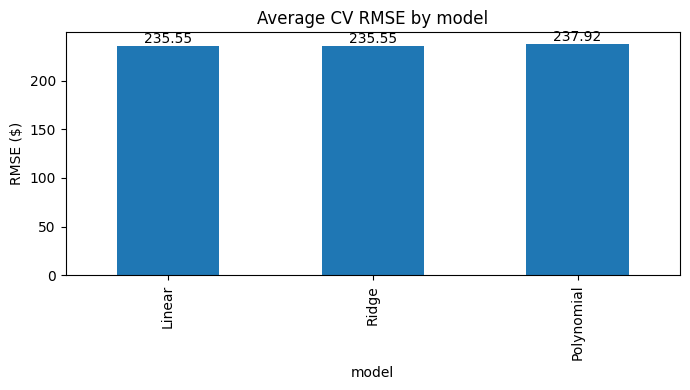

In [12]:

summary = (model_results.groupby("model")[["MAE_mean", "RMSE_mean", "RMSE_std", "R2_mean"]]
           .mean().round(3).sort_values("RMSE_mean"))
display(summary)

best_model_name = summary.index[0]
print("Best model by average CV RMSE:", best_model_name)

# This row is descriptive only; it does NOT select the final holdout.
best_row = model_results[model_results.model == best_model_name].sort_values("RMSE_mean").iloc[0]
print("Best development-data configuration (not the final holdout):")
display(best_row.to_frame().T)

print("Final holdout was reserved in advance:", final_test_size, final_random_state)

ax = summary["RMSE_mean"].plot(kind="bar", figsize=(7, 4), title="Average CV RMSE by model")
plt.ylabel("RMSE ($)")
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()



## 6.4 Final Untouched Test Evaluation

**Question:** How does the selected model perform when its matching held-out test set is evaluated once?

In [13]:

# Evaluate the selected model ONCE on the final untouched holdout.
selected_ts, selected_rs = final_test_size, final_random_state

X_train, X_test = X_development, X_final_test
y_train, y_test = y_development, y_final_test

final_model = regression_pipeline(best_model_name, degree=degree, alpha=alpha)
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

print("Five predictors selected from development data:",
      final_model.named_steps["feature_selection"].predictors_)

test_mae = mean_absolute_error(y_test, pred)
test_rmse = np.sqrt(mean_squared_error(y_test, pred))
test_r2 = r2_score(y_test, pred)

test_results = pd.DataFrame([{
    "model": best_model_name,
    "test_size": selected_ts,
    "random_state": selected_rs,
    "Test MAE": round(test_mae, 2),
    "Test RMSE": round(test_rmse, 2),
    "Test R2": round(test_r2, 3)
}])

display(test_results)




Five predictors selected from development data: ['longitude', 'availability_365', 'calculated_host_listings_count', 'minimum_nights', 'number_of_reviews']


,model,test_size,random_state,Test MAE,Test RMSE,Test R2
0,Linear,0.1,42,85.22,134.9,0.029


In [14]:

# Prepare cross-validation results for Excel
excel_results = pd.DataFrame({
    "Model": model_results["model"],
    "Feature_Set": model_results["feature_set"],
    "CV_or_Split": (
        "5-fold CV | Test size: "
        + model_results["test_size"].astype(str)
        + " | Seed: "
        + model_results["random_state"].astype(str)
    ),
    "Best_Params": model_results["model"].map({
        "Linear": "Default",
        "Ridge": "alpha=1.0",
        "Polynomial": "degree=3"
    }),
    "MAE": model_results["MAE_mean"],
    "RMSE": model_results["RMSE_mean"],
    "R2": model_results["R2_mean"],
    "Notes": (
        "CV standard deviations: MAE="
        + model_results["MAE_std"].astype(str)
        + ", RMSE="
        + model_results["RMSE_std"].astype(str)
        + ", R2="
        + model_results["R2_std"].astype(str)
    )
})

# Add final holdout test results
final_row = pd.DataFrame([{
    "Model": best_model_name,
    "Feature_Set": "Top 5 training-selected features",
    "CV_or_Split": "Final untouched holdout",
    "Best_Params": (
        "alpha=1.0" if best_model_name == "Ridge"
        else "degree=3" if best_model_name == "Polynomial"
        else "Default"
    ),
    "MAE": test_mae,
    "RMSE": test_rmse,
    "R2": test_r2,
    "Notes": "Final test size=0.10, seed=42"
}])

excel_results = pd.concat(
    [excel_results, final_row],
    ignore_index=True
)

# Save Excel workbook
excel_results.to_excel(
    OUTPUT_DIR / "Regression_Results.xlsx",
    sheet_name="Regression_Results",
    index=False
)

display(excel_results)
print("Excel file saved successfully!")


,Model,Feature_Set,CV_or_Split,Best_Params,MAE,RMSE,R2,Notes
0,Linear,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 0,Default,87.622000,250.414000,0.028000,"CV standard deviations: MAE=5.443, RMSE=86.856..."
1,Polynomial,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 0,degree=3,88.391000,254.847000,-0.019000,"CV standard deviations: MAE=4.774, RMSE=84.709..."
2,Ridge,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 0,alpha=1.0,87.621000,250.413000,0.028000,"CV standard deviations: MAE=5.442, RMSE=86.856..."
3,Linear,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 42,Default,87.319000,246.183000,0.028000,"CV standard deviations: MAE=7.52, RMSE=96.692,..."
4,Polynomial,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 42,degree=3,87.251000,247.993000,0.000000,"CV standard deviations: MAE=7.334, RMSE=94.154..."
5,Ridge,Top 5 training-selected features,5-fold CV | Test size: 0.1 | Seed: 42,alpha=1.0,87.318000,246.183000,0.028000,"CV standard deviations: MAE=7.521, RMSE=96.693..."
6,Linear,Top 5 training-selected features,5-fold CV | Test size: 0.25 | Seed: 0,Default,83.021000,203.351000,0.040000,"CV standard deviations: MAE=5.754, RMSE=78.993..."
7,Polynomial,Top 5 training-selected features,5-fold CV | Test size: 0.25 | Seed: 0,degree=3,83.142000,204.748000,0.024000,"CV standard deviations: MAE=6.525, RMSE=78.458..."
8,Ridge,Top 5 training-selected features,5-fold CV | Test size: 0.25 | Seed: 0,alpha=1.0,83.020000,203.351000,0.040000,"CV standard deviations: MAE=5.754, RMSE=78.994..."
9,Linear,Top 5 training-selected features,5-fold CV | Test size: 0.25 | Seed: 42,Default,87.696000,260.172000,0.036000,"CV standard deviations: MAE=5.647, RMSE=96.48,..."


Excel file saved successfully!


## 6.5 Actual-vs-Predicted, Residuals, and Large Errors

**Question:** Where does the selected model perform well or poorly, and what explains large errors or outliers?

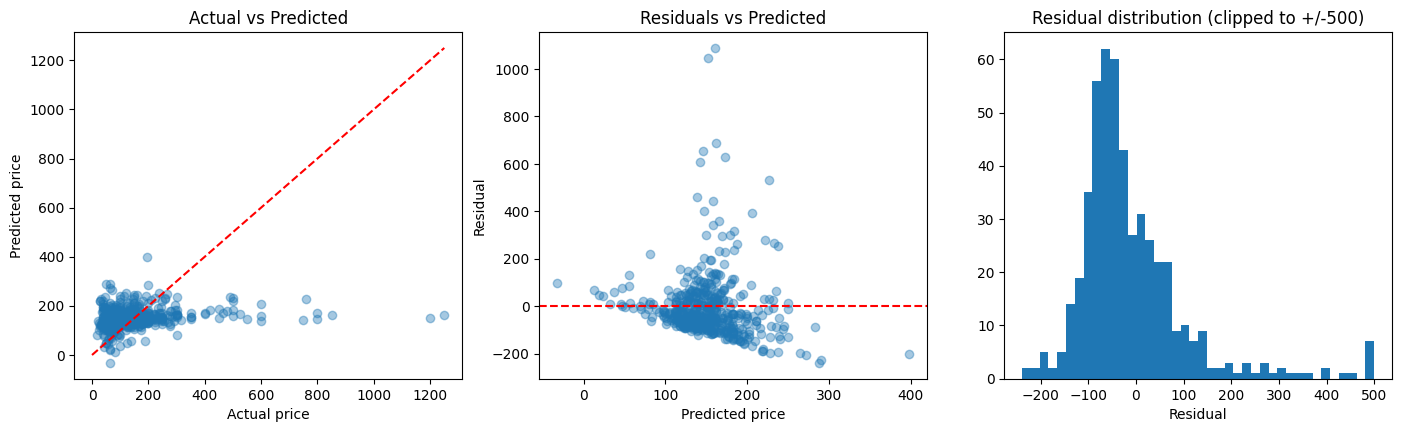

,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,actual_price,predicted_price,abs_error
3758,40.73532,-73.99473,1,0,NaN,1,0,1250,161.2,1088.8
14459,40.73546,-73.98057,2,0,NaN,1,0,1200,152.1,1047.9
16140,40.74574,-73.99633,2,10,0.26,1,10,850,162.2,687.8
22069,40.76305,-73.97841,1,19,0.69,2,0,800,145.7,654.3
35809,40.72345,-73.99943,2,36,3.88,1,90,800,172.6,627.4
12788,40.73027,-73.98759,3,97,2.22,1,47,750,142.2,607.8
6978,40.72177,-74.00356,14,1,0.04,1,292,760,226.7,533.3
30923,40.72574,-73.98272,5,70,4.49,3,6,600,139.2,460.8
21848,40.68326,-73.97796,6,7,0.36,1,42,600,158.3,441.7
21082,40.68640,-73.96882,3,1,0.42,1,15,550,147.2,402.8


,mean absolute error
room_type,
Entire home/apt,89.0
Private room,80.6
Shared room,103.8


In [15]:
residuals= y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(y_test, pred, alpha=0.4)
axes[0].plot([0, y_test.max()], [0, y_test.max()], "r--")
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")

axes[1].scatter(pred, residuals, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted price")
axes[1].set_ylabel("Residual")

axes[2].hist(residuals.clip(-500, 500), bins=40)
axes[2].set_title("Residual distribution (clipped to +/-500)")
axes[2].set_xlabel("Residual")


plt.show()

# Ten largest errors
errors = X_test.copy()
errors["actual_price"] = y_test
errors["predicted_price"] = pred.round(1)
errors["abs_error"] = residuals.abs().round(1)
display(errors.sort_values("abs_error", ascending=False).head(10))

# Error by room type
display(errors.groupby(df_model["room_type"])["abs_error"].mean().round(1).to_frame("mean absolute error"))

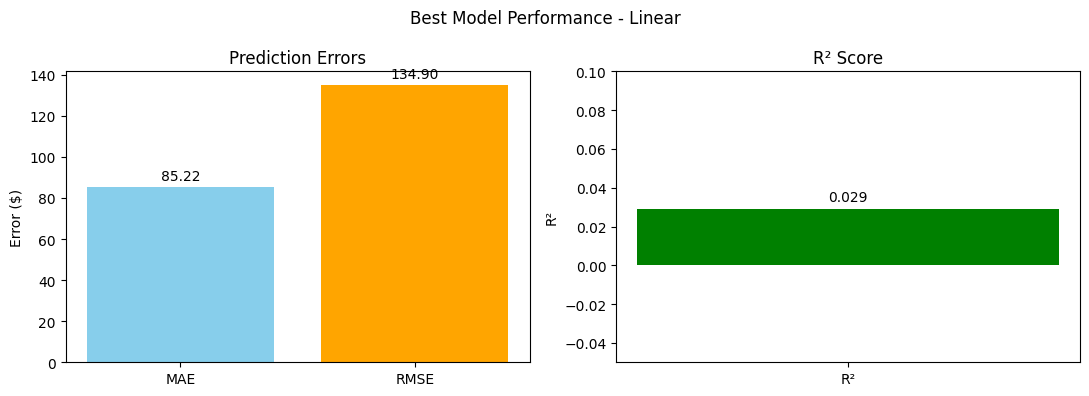

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Chart 1: MAE and RMSE
bars = axes[0].bar(
    ['MAE', 'RMSE'],
    [test_mae, test_rmse],
    color=['skyblue', 'orange']
)

axes[0].set_title('Prediction Errors')
axes[0].set_ylabel('Error ($)')

# Add labels above bars
axes[0].bar_label(bars, fmt='%.2f', padding=3)

# Chart 2: R-squared
bars2 = axes[1].bar(
    ['R²'],
    [test_r2],
    color='green'
)

axes[1].set_title('R² Score')
axes[1].set_ylabel('R²')

# Add R² value
axes[1].bar_label(bars2, fmt='%.3f', padding=3)
axes[1].set_ylim(
    min(0, test_r2) - 0.05,
    max(0.1, test_r2 + 0.05)
)

fig.suptitle(f'Best Model Performance - {best_model_name}')

plt.tight_layout()

# Save chart
plt.savefig(
    'Best_Model_Performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()